# Reto: clasificación de cobertura terrestre (landuse)

Se eligieron tres clases del dataset local: `denseresidential`, `harbor` y
`river`. El objetivo es comparar tres enfoques de **aprendizaje profundo**
—una CNN secuencial, una arquitectura no secuencial y un Transformer— usando el
mismo split y las mismas métricas.

| Grupo | Modelo | Cuaderno | Resultados |
|---|---|---|---|
| CNN | CNN base y CNN mejorada | `LandUseCNN.ipynb` | `resultados/cnn/` |
| DL no secuencial | DenseNet121 preentrenada + fine-tuning | `LandUseDenseNet.ipynb` | `resultados/densenet/` |
| Transformer | Swin desde cero | `LandUseSWIN.ipynb` | `resultados/swin/` |


## Protocolo

* **Dataset**: 1.500 imágenes PNG (500 por clase), redimensionadas a 128×128.
* **Split**: 75 % train, 15 % validación y 25 % test, estratificado, semilla 20
  (`resultados/split.json`). El test no se usa para entrenar ni para early stopping.
* **Métricas**: accuracy, precisión/recall/F1 macro, Cohen's kappa, ROC-AUC,
  matriz de confusión, IC 95 % por bootstrap y test exacto de McNemar.
* **Evidencia**: cada modelo guarda `metrics.json`, `predictions.csv`,
  `classification_report.txt`, `history.csv` y su modelo entrenado.

## Carga de resultados y tabla resumen

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import f1_score

import common_landuse as cl

sns.set_theme(style="whitegrid", context="notebook")
comparison_dir = cl.result_dir("comparacion")
comparison_dir.mkdir(parents=True, exist_ok=True)

order = ["cnn/base", "cnn/mejorada", "densenet", "swin"]
results = cl.load_all_results()
results["order"] = results["folder"].map({folder: index for index, folder in enumerate(order)})
results = results.sort_values("order").drop(columns="order").reset_index(drop=True)


def bootstrap_f1_ci(y_true, y_pred, n_boot=2000, seed=cl.SEED):
    rng = np.random.default_rng(seed)
    scores = []
    for _ in range(n_boot):
        indices = rng.integers(0, len(y_true), len(y_true))
        scores.append(f1_score(y_true[indices], y_pred[indices], average="macro"))
    return np.percentile(scores, [2.5, 97.5])


predictions = {}
interval_rows = []
for _, row in results.iterrows():
    frame = cl.load_predictions(row["folder"])
    predictions[row["model"]] = frame
    accuracy_low, accuracy_high = cl.bootstrap_accuracy_ci(
        frame["true_class"], frame["predicted_class"]
    )
    f1_low, f1_high = bootstrap_f1_ci(frame["true_class"], frame["predicted_class"])
    interval_rows.append(
        {
            "model": row["model"],
            "accuracy_low": accuracy_low,
            "accuracy_high": accuracy_high,
            "f1_low": f1_low,
            "f1_high": f1_high,
        }
    )

results = results.merge(pd.DataFrame(interval_rows), on="model")
summary_columns = [
    "model",
    "family",
    "accuracy",
    "f1_macro",
    "precision_macro",
    "recall_macro",
    "cohen_kappa",
    "roc_auc_ovr_macro",
    "parameters",
    "training_seconds",
    "inference_ms_per_image",
    "epochs",
]
summary = results[summary_columns].copy()
summary.to_csv(comparison_dir / "model_summary.csv", index=False)

display_summary = summary.rename(
    columns={
        "model": "Modelo",
        "family": "Familia",
        "accuracy": "Accuracy",
        "f1_macro": "F1 macro",
        "precision_macro": "Precisión macro",
        "recall_macro": "Recall macro",
        "cohen_kappa": "Kappa",
        "roc_auc_ovr_macro": "AUC OVR",
        "parameters": "Parámetros",
        "training_seconds": "Entrenamiento (s)",
        "inference_ms_per_image": "Inferencia (ms/img)",
        "epochs": "Épocas",
    }
)
display_summary["Familia"] = display_summary["Familia"].replace(
    {"DL (non-sequential)": "DL (no secuencial)"}
)
display_summary["Parámetros"] = display_summary["Parámetros"].map(
    lambda value: f"{int(value):,}"
)
display_summary["Entrenamiento (s)"] = display_summary["Entrenamiento (s)"].map(
    lambda value: f"{value:,.0f}"
)
display_summary["Inferencia (ms/img)"] = display_summary["Inferencia (ms/img)"].map(
    lambda value: f"{value:.1f}"
)
display_summary.round(4)

,Modelo,Familia,Accuracy,F1 macro,Precisión macro,Recall macro,Kappa,AUC OVR,Parámetros,Entrenamiento (s),Inferencia (ms/img),Épocas
0,CNN base,CNN,0.8773,0.8755,0.8891,0.8773,0.816,0.9842,"30,611",76,2.5,15
1,CNN mejorada,CNN,0.9760,0.9760,0.9761,0.9760,0.964,0.9990,"305,251","2,063",13.3,29
2,DenseNet121,DL (no secuencial),0.9893,0.9893,0.9897,0.9893,0.984,0.9996,"7,040,579",698,67.8,15
3,Swin Transformer,Transformer,0.9653,0.9654,0.9662,0.9653,0.948,0.9929,"5,133,871",833,23.2,40


## Figura 1: accuracy y F1 macro con IC 95 %

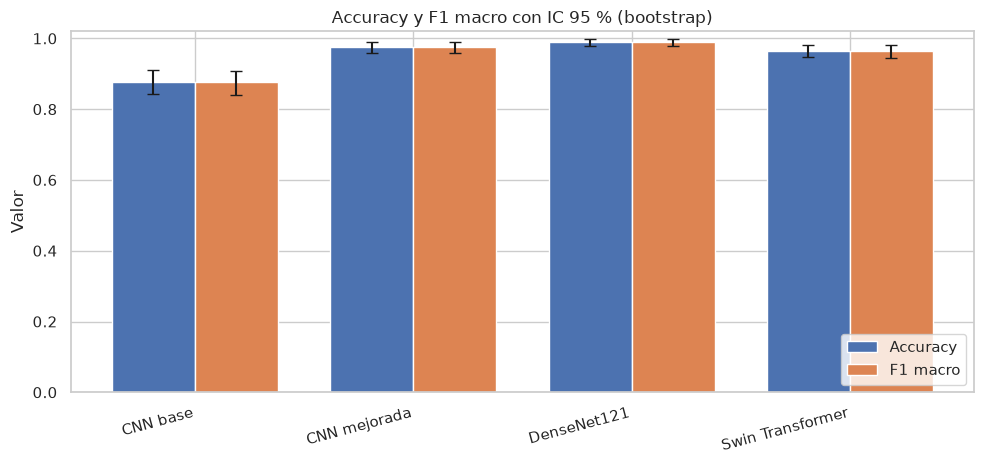

In [2]:
fig, ax = plt.subplots(figsize=(10, 4.8))
positions = np.arange(len(results))
width = 0.38

ax.bar(
    positions - width / 2,
    results["accuracy"],
    width,
    yerr=[
        results["accuracy"] - results["accuracy_low"],
        results["accuracy_high"] - results["accuracy"],
    ],
    capsize=4,
    label="Accuracy",
)
ax.bar(
    positions + width / 2,
    results["f1_macro"],
    width,
    yerr=[
        results["f1_macro"] - results["f1_low"],
        results["f1_high"] - results["f1_macro"],
    ],
    capsize=4,
    label="F1 macro",
)
ax.set_xticks(positions, results["model"], rotation=15, ha="right")
ax.set_ylim(0, 1.02)
ax.set_ylabel("Valor")
ax.set_title("Accuracy y F1 macro con IC 95 % (bootstrap)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(comparison_dir / "barras_accuracy_f1.png", dpi=150, bbox_inches="tight")
plt.show()

## Figura 2: matrices de confusión

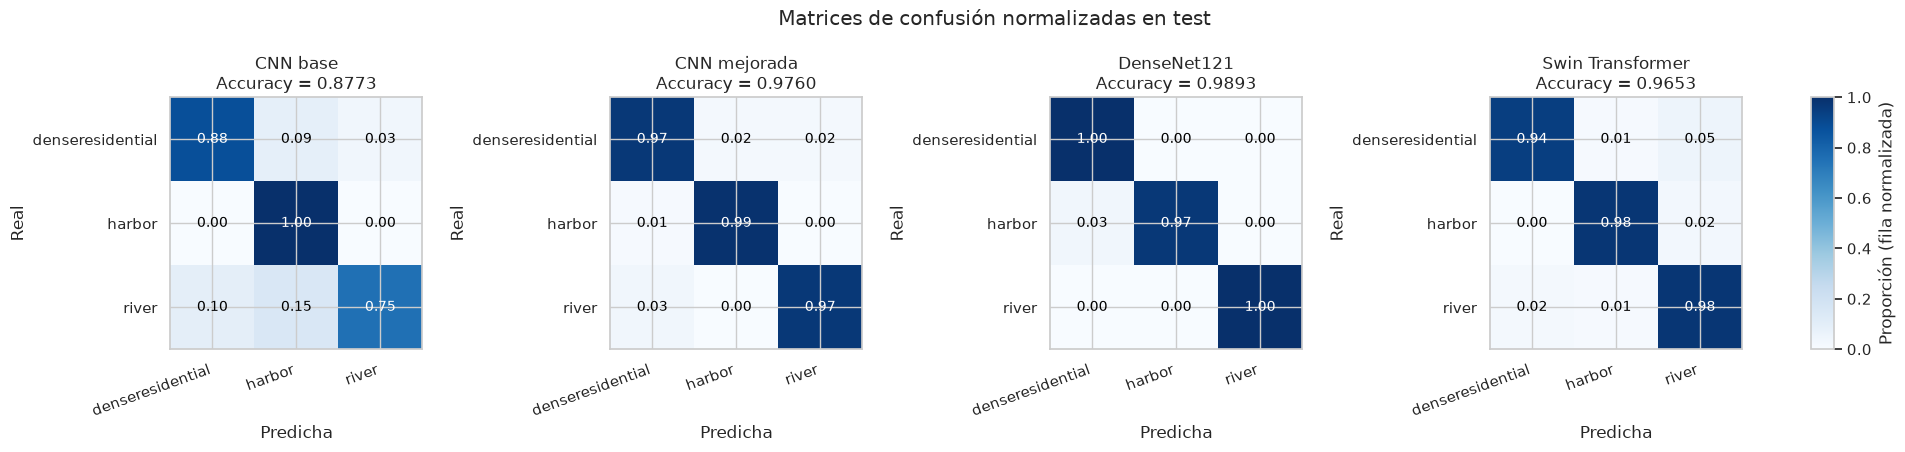

In [3]:
fig, axes = plt.subplots(1, len(results), figsize=(4.8 * len(results), 4.2))
for ax, (_, row) in zip(np.atleast_1d(axes), results.iterrows()):
    metrics = cl.load_metrics(row["folder"])
    matrix = np.asarray(metrics["confusion_matrix"], dtype=float)
    matrix = matrix / matrix.sum(axis=1, keepdims=True)
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(cl.CLASSES)), cl.CLASSES, rotation=20, ha="right")
    ax.set_yticks(range(len(cl.CLASSES)), cl.CLASSES)
    for row_index in range(len(cl.CLASSES)):
        for column_index in range(len(cl.CLASSES)):
            value = matrix[row_index, column_index]
            ax.text(
                column_index,
                row_index,
                f"{value:.2f}",
                ha="center",
                va="center",
                color="white" if value > 0.5 else "black",
                fontsize=10,
            )
    ax.set_title(f"{row['model']}\nAccuracy = {row['accuracy']:.4f}")
    ax.set_xlabel("Predicha")
    ax.set_ylabel("Real")

fig.subplots_adjust(left=0.06, right=0.90, bottom=0.22, top=0.82, wspace=0.50)
colorbar_ax = fig.add_axes([0.925, 0.22, 0.012, 0.60])
fig.colorbar(image, cax=colorbar_ax, label="Proporción (fila normalizada)")
fig.suptitle("Matrices de confusión normalizadas en test", y=1.03)
fig.savefig(comparison_dir / "matrices_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

## Figura 3: curvas de aprendizaje

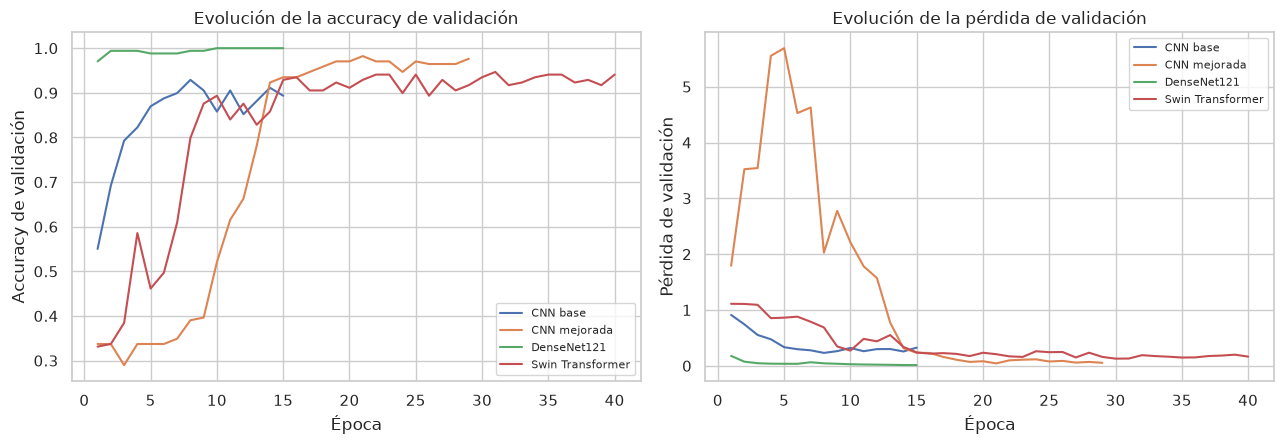

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for _, row in results.iterrows():
    history = cl.load_history(row["folder"])
    axes[0].plot(history.index, history["val_accuracy"], label=row["model"])
    axes[1].plot(history.index, history["val_loss"], label=row["model"])

axes[0].set_xlabel("Época")
axes[0].set_ylabel("Accuracy de validación")
axes[0].set_title("Evolución de la accuracy de validación")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Pérdida de validación")
axes[1].set_title("Evolución de la pérdida de validación")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(comparison_dir / "curvas_aprendizaje.png", dpi=150, bbox_inches="tight")
plt.show()

## Figura 4: F1 por clase

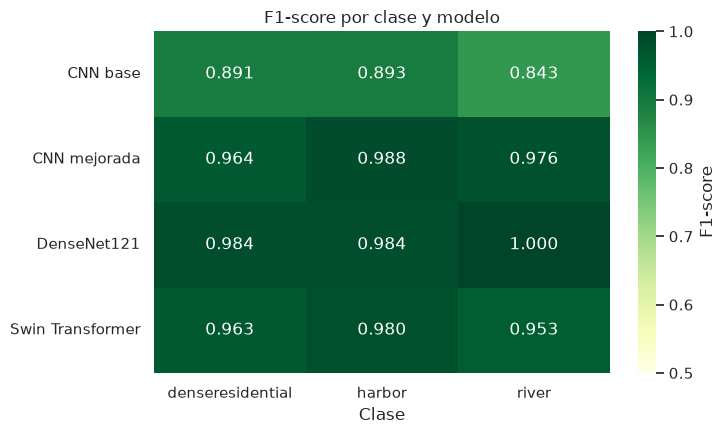

,denseresidential,harbor,river
model,,,
CNN base,0.8907,0.8929,0.8430
CNN mejorada,0.9641,0.9880,0.9758
DenseNet121,0.9843,0.9837,1.0000
Swin Transformer,0.9633,0.9799,0.9531


In [5]:
f1_columns = [f"f1_{class_name}" for class_name in cl.CLASSES]
f1_matrix = results.set_index("model")[f1_columns]
f1_matrix.columns = cl.CLASSES

fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.heatmap(
    f1_matrix,
    annot=True,
    fmt=".3f",
    cmap="YlGn",
    vmin=0.5,
    vmax=1,
    ax=ax,
    cbar_kws={"label": "F1-score"},
)
ax.set_title("F1-score por clase y modelo")
ax.set_xlabel("Clase")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(comparison_dir / "heatmap_f1_por_clase.png", dpi=150, bbox_inches="tight")
plt.show()
f1_matrix.round(4)

## Validación estadística: McNemar

In [6]:
names = results["model"].tolist()
pvalues = pd.DataFrame(np.ones((len(names), len(names))), index=names, columns=names)
for row_name in names:
    for column_name in names:
        if row_name == column_name:
            continue
        frame_row = predictions[row_name]
        frame_column = predictions[column_name]
        pvalues.loc[row_name, column_name] = cl.mcnemar_pvalue(
            frame_row["true_class"],
            frame_row["predicted_class"],
            frame_column["predicted_class"],
        )

pvalues.to_csv(comparison_dir / "mcnemar_pvalues.csv", float_format="%.4f")
pvalues.round(4)

,CNN base,CNN mejorada,DenseNet121,Swin Transformer
CNN base,1.0,0.0000,0.0000,0.0000
CNN mejorada,0.0,1.0000,0.2266,0.5034
DenseNet121,0.0,0.2266,1.0000,0.0490
Swin Transformer,0.0,0.5034,0.0490,1.0000


## Conclusiones

- **Protocolo y modelos comparados.** Se usaron 1.500 imágenes de
  `denseresidential`, `harbor` y `river`, con un split común de 75/15/25 y test
  intacto. Se compararon tres enfoques de aprendizaje profundo: una CNN secuencial
  (base y mejorada), DenseNet121 preentrenada en ImageNet y Swin Transformer
  desde cero.

- **Resultados principales.** DenseNet121 obtuvo la mejor accuracy (98,93 %,
  IC 95 % 97,87–99,73 %) y el mejor F1 macro (98,93 %). La CNN mejorada quedó
  muy cerca (97,60 %, IC 96,00–98,93 %) y Swin alcanzó 96,53 % (IC 94,67–98,13 %).
  La CNN base se quedó en 87,73 % (IC 84,27–90,93 %), casi diez puntos por debajo
  de la CNN mejorada. El F1 por clase es homogéneo en las tres clases.

- **DenseNet frente a CNN mejorada.** La diferencia de 1,33 puntos no es
  estadísticamente significativa (McNemar p = 0,2266), mientras que la CNN base
  frente a cualquiera de los tres modelos nuevos da p ≈ 0. DenseNet necesita
  7,0 M de parámetros y 698 s de entrenamiento, frente a 0,31 M y 2.063 s de la
  CNN mejorada. Su ventaja es converger en 15 épocas gracias al preentrenamiento,
  no una superioridad aplastante en accuracy.

- **Swin y el efecto del preentrenamiento.** Swin desde cero alcanzó 96,53 %,
  competitivo pero por debajo de DenseNet; su diferencia con DenseNet es límite
  (p = 0,0490) y con la CNN mejorada no es significativa (p = 0,5034). Entrenar
  un Transformer con 956 imágenes exige 40 épocas y una configuración cuidadosa.
  El resultado refuerza que, en visión, el preentrenamiento pesa tanto o más que
  la arquitectura.

- **Coste y despliegue.** La CNN base es la más barata (30.611 parámetros,
  2,5 ms/imagen), pero su accuracy es baja. La CNN mejorada ofrece la mejor
  relación precisión/coste (305.251 parámetros, 13,3 ms/imagen). DenseNet es la
  más precisa pero también la más lenta en inferencia (67,8 ms/imagen); Swin
  queda en un punto intermedio (23,2 ms/imagen).

- **Elección final.** DenseNet121 es la mejor opción si prima la precisión; la CNN
  mejorada es la opción más equilibrada para despliegue. El Grad-CAM de DenseNet
  concentra las activaciones en agua, vegetación y tejido urbano, lo que respalda
  su interpretabilidad.